# Module 1: E-Commerce Data Cleaning, Preprocessing & Deep EDA
### Author: Senior Data Scientist & ML Engineer Portfolio
---
### Objectives:
1. **Data Ingestion**: Load the UCI Online Retail dataset (541k+ transactional rows).
2. **Data Cleaning & Auditing**: Handle missing values, filter non-product records, and separate cancellations.
3. **Dual Dataset Architecture**:
   - Store-level cleaned dataset (for aggregate macro sales forecasting).
   - Customer-centric dataset (for RFM, churn, and collaborative filtering).
4. **Exploratory Data Analysis (EDA)**: Executive KPIs, Pareto principle in product revenues, temporal purchase rhythms, and country concentration.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Environment libraries successfully loaded.")


Environment libraries successfully loaded.


## 1. Data Ingestion & Schema Inspection
We load the preprocessed CSV version of the raw dataset. Each row is an invoice item representing an individual purchase transaction.


In [2]:
# Load raw dataset
data_path = Path('../data/raw/online_retail.csv')
if not data_path.exists():
    raise FileNotFoundError("Raw CSV not found. Please run src/data/ingest.py first.")

df_raw = pd.read_csv(
    data_path,
    dtype={'InvoiceNo': str, 'StockCode': str, 'CustomerID': str},
    parse_dates=['InvoiceDate']
)

print(f"Total Raw Records: {len(df_raw):,}")
print(f"Total Features: {df_raw.shape[1]}")
df_raw.head()


Total Raw Records: 541,909
Total Features: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Missing Value & Anomaly Diagnostics
Real transactional data contains critical gaps. We analyze null counts and assess business reasons behind missing customer identifiers (Guest Checkouts).


In [3]:
missing_summary = pd.DataFrame({
    'Missing_Count': df_raw.isnull().sum(),
    'Percentage (%)': (df_raw.isnull().sum() / len(df_raw) * 100).round(2)
})
missing_summary[missing_summary['Missing_Count'] > 0]


,Missing_Count,Percentage (%)
Description,1454,0.27
CustomerID,135080,24.93


## 3. Handling Cancellations & Negative Quantities
In the UK Online Retail dataset, invoice numbers prefixed with **'C'** denote customer cancellations or returns.
These rows typically carry negative quantities.


In [4]:
cancellations = df_raw[df_raw['InvoiceNo'].str.startswith('C', na=False) | (df_raw['Quantity'] < 0)]
print(f"Total Cancellation / Return Records: {len(cancellations):,} ({len(cancellations)/len(df_raw)*100:.2f}%)")
cancellations.head(3)


Total Cancellation / Return Records: 10,624 (1.96%)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom


## 4. Pipeline Execution: Creating Dual-Cleaned Datasets
We invoke our production cleaner from `src.data.clean.ECommerceDataCleaner` to produce:
1. `online_retail_cleaned.csv`: Validated store transactions.
2. `online_retail_customer_centric.csv`: Confirmed customer-identified transactions.


In [5]:
import sys
sys.path.append('..')
from src.data.clean import ECommerceDataCleaner

cleaner = ECommerceDataCleaner(raw_csv_path=Path('../data/raw/online_retail.csv'))
cleaner.clean_transactions()
audit = cleaner.generate_audit_summary()

for metric, val in audit.items():
    print(f"{metric:25s}: {val}")


[Cleaner] Loading raw transactions from ../data/raw/online_retail.csv...


[Cleaner] Loaded 541,909 records across 8 columns.


[Cleaner] Saved store-wide cleaned dataset (536,636 rows) to: /Users/aryangupta/Desktop/e-commerce/data/processed/online_retail_cleaned.csv


[Cleaner] Saved customer-centric dataset (396,470 rows, 4,334 unique customers) to: /Users/aryangupta/Desktop/e-commerce/data/processed/online_retail_customer_centric.csv
raw_record_count         : 541909
cleaned_record_count     : 536636
customer_centric_count   : 396470
unique_customers         : 4334
unique_products          : 3660
date_range_start         : 2010-12-01 08:26:00
date_range_end           : 2011-12-09 12:50:00
cancellations_count      : 8706
guest_checkouts_count    : 131626
gross_revenue            : 8767752.650000002


## 5. Executive Business KPIs
High-level operational health indicators derived from clean transactional records.


In [6]:
from src.data.eda import ECommerceEDA

eda = ECommerceEDA(data_path=Path('../data/processed/online_retail_cleaned.csv'))
kpis = eda.compute_executive_kpis()

pd.DataFrame(list(kpis.items()), columns=['Business KPI', 'Value'])


[EDA] Loading processed data from ../data/processed/online_retail_cleaned.csv...


,Business KPI,Value
0,Total Gross Revenue (£),10279169.87
1,Total Completed Invoices,19776.00
2,Total Units Sold,5577275.00
3,Average Order Value (AOV £),519.78
4,Unique Registered Customers,4334.00
5,Unique Active SKUs,3804.00
6,Cancellation Rate (%),1.62


## 6. Product Performance & Pareto Principle (80/20 Rule)
Which top products drive the greatest revenue and volume?


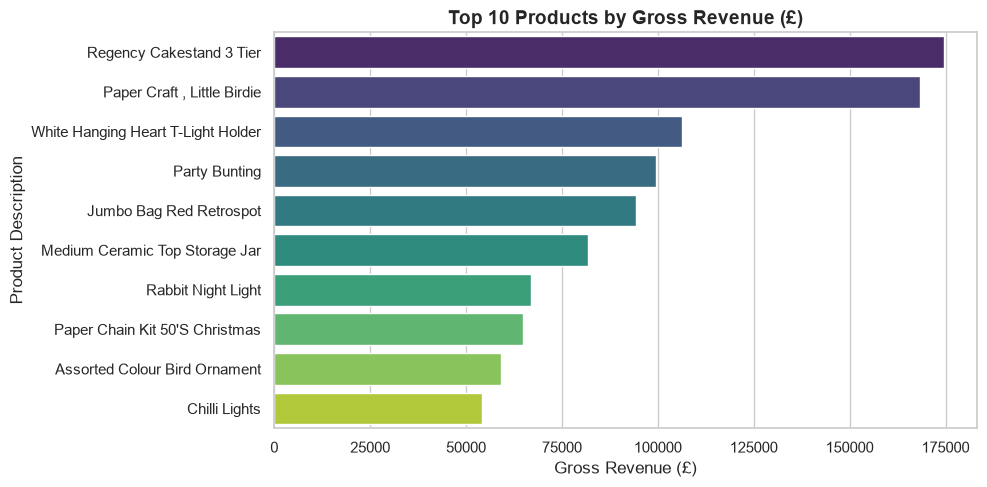

In [7]:
top_products = eda.get_top_selling_products(10)
plt.figure(figsize=(10, 5))
sns.barplot(data=top_products, x='TotalRevenue', y='Description', palette='viridis')
plt.title('Top 10 Products by Gross Revenue (£)', fontsize=14, weight='bold')
plt.xlabel('Gross Revenue (£)')
plt.ylabel('Product Description')
plt.tight_layout()
plt.show()


## 7. Temporal Sales Trends & Seasonality
Analyzing monthly revenue trajectories to identify Q4 holiday shopping peaks.


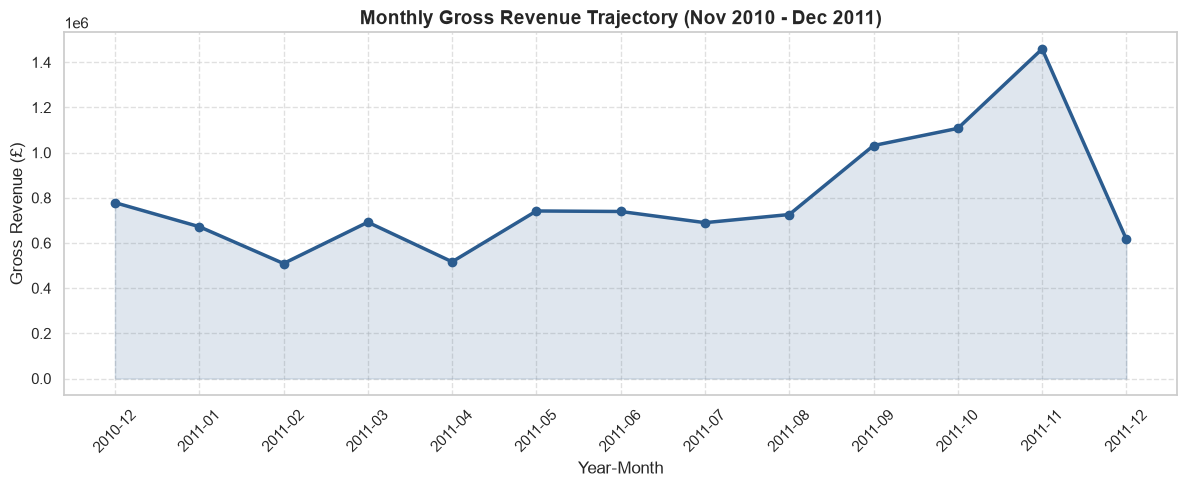

In [8]:
monthly_sales = eda.get_monthly_revenue_trend()
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales['YearMonth'], monthly_sales['MonthlyRevenue'], marker='o', linewidth=2.5, color='#2b5c8f')
plt.fill_between(range(len(monthly_sales)), monthly_sales['MonthlyRevenue'], color='#2b5c8f', alpha=0.15)
plt.title('Monthly Gross Revenue Trajectory (Nov 2010 - Dec 2011)', fontsize=14, weight='bold')
plt.xlabel('Year-Month')
plt.ylabel('Gross Revenue (£)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 8. Geographic Revenue Concentration
Examining domestic (UK) vs international market distribution.


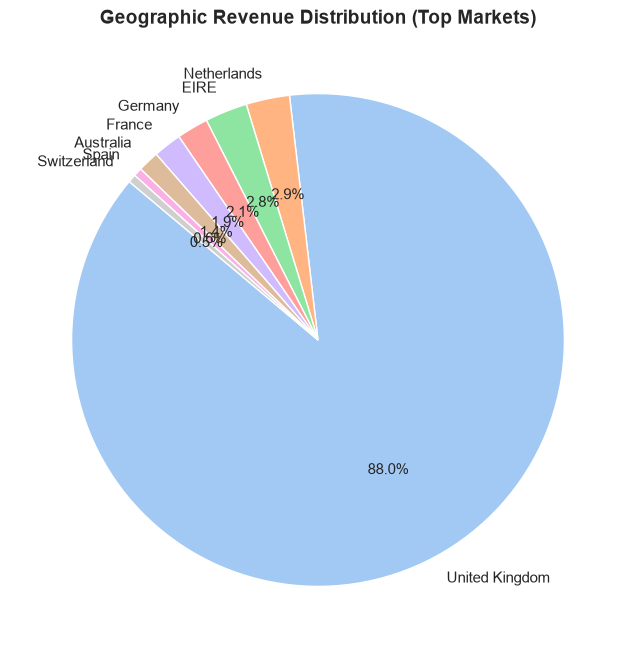

In [9]:
country_share = eda.get_country_breakdown(8)
plt.figure(figsize=(8, 8))
plt.pie(country_share['Revenue'], labels=country_share['Country'], autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Geographic Revenue Distribution (Top Markets)', fontsize=14, weight='bold')
plt.show()
